In [ ]:
'''
This is the prototype of their SNN, which uses simple regression, but with 2 different models, that have 100 output neurons instead of 200. 
The idea is that SBP and DBP predictions are separate so they can use their own input features and weights to more accurately predict SBP and DBP values


[spikegen] Final CV MAE's: 
SBP: 12.6850 ± 1.9095
DBP: 7.6747 ± 1.7814

After stratified sampling on the folds (beta = 0.7)
[spikegen] Final CV MAE's: 
SBP: 8.0082 ± 0.3506
DBP: 4.6083 ± 0.1942

After stratified sampling on the folds (beta = 0.95)
[spikegen] Final CV MAE's: 
SBP: 6.0907 ± 0.1492
DBP: 3.9164 ± 0.1919
'''
import torch
import torch.nn as nn
import torch.optim as optim
import snntorch as snn
from snntorch import spikegen
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader, TensorDataset
from snntorch import surrogate, functional as SF
from scipy.stats import beta as beta_dist
import pickle
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold


In [89]:
def plot_predictions(all_true, all_predictions, label, fold, samplingRange):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].scatter(all_true, all_predictions, alpha=0.4, s=10)
    axes[0].plot([all_true.min(), all_true.max()],
                 [all_true.min(), all_true.max()], 'r--', label='Perfect prediction')
    axes[0].set_xlabel(f"True {label}")
    axes[0].set_ylabel(f"Predicted {label}")
    axes[0].set_title(f"Fold {fold+1} - Predicted vs True {label}")
    axes[0].legend()

    axes[1].plot(all_true[:samplingRange], label=f'True {label}', alpha=0.8)
    axes[1].plot(all_predictions[:samplingRange], label=f'Predicted {label}', alpha=0.8)
    axes[1].set_xlabel("Sample")
    axes[1].set_ylabel(f"{label} (mmHg)")
    axes[1].set_title(f"Fold {fold+1} - First {samplingRange} Samples")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [90]:
def combined_beta_cdf(vsignal):
    v = float(vsignal)
    if v < 0.5:
        vnorm = 2 * v
        return beta_dist.cdf(vnorm, a=1.0, b=0.75)
    else:
        vnorm = 2 * v - 1
        return beta_dist.cdf(vnorm, a=0.75, b=1.0)

'''
def rate_encoding_beta(X, timesteps=50):
    batch_size, N_features = X.shape
    spike_train = torch.zeros(timesteps, batch_size, N_features)
    for b in range(batch_size):
        for f in range(N_features):
            Pfr = combined_beta_cdf(X[b, f])
            spike_train[:, b, f] = torch.bernoulli(Pfr * torch.ones(timesteps))
    return spike_train
'''

def rate_encoding_beta(X, timesteps=50):
    # compute all beta CDF values at once using numpy, then convert back to tensor
    X_np  = X.clamp(0.0, 1.0).numpy()
    probs = np.vectorize(combined_beta_cdf)(X_np)
    probs = torch.tensor(probs, dtype=torch.float32)
    probs = probs.unsqueeze(0).expand(timesteps, -1, -1)
    return torch.bernoulli(probs)


'''
def rate_encoding_uniform(X, timesteps=50):
    batch_size, N_features = X.shape
    spike_train = torch.zeros(timesteps, batch_size, N_features)
    for b in range(batch_size):
        for f in range(N_features):
            Pfr = X[b, f]
            spike_train[:, b, f] = torch.bernoulli(Pfr * torch.ones(timesteps))
    return spike_train
'''

def rate_encoding_uniform(X, timesteps=50):
    probs = X.clamp(0.0, 1.0).unsqueeze(0).expand(timesteps, -1, -1)  # [T, batch, features]
    return torch.bernoulli(probs)   

def encode_batch(x, num_steps, method):
    '''
    x      : [batch, n_features] normalized to [0,1]
    method : 'spikegen' | 'uniform' | 'beta'
    Returns: [num_steps, batch, n_features]
    '''
    if method == 'spikegen':
        return spikegen.rate(x, num_steps=num_steps)
    elif method == 'uniform':
        return rate_encoding_uniform(x, timesteps=num_steps)
    elif method == 'beta':
        return rate_encoding_beta(x, timesteps=num_steps)
    else:
        raise ValueError(f'Unknown encoding: {method}')
    

In [91]:
num_steps = 100  # changed from 40 to 100

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

class Net(nn.Module):
    def __init__(self, num_inputs, num_hidden, num_hidden2,
                 num_outputs, beta_val, num_steps=100):
        super().__init__()
        self.num_steps = num_steps
        self.fc1   = nn.Linear(num_inputs, num_hidden)
        self.lif1  = snn.Leaky(beta=beta_val)           # learn_beta removed
        self.fc2   = nn.Linear(num_hidden, num_hidden2)
        self.lif2  = snn.Leaky(beta=beta_val)           # learn_beta removed
        self.fc3   = nn.Linear(num_hidden2, num_outputs)
        self.lif3  = snn.Leaky(beta=beta_val)           # learn_beta removed
        # dropout layers removed

    def forward(self, xf):
        mem1 = self.lif1.reset_mem()   # init_leaky() → reset_mem()
        mem2 = self.lif2.reset_mem()
        mem3 = self.lif3.reset_mem()
        spk_rec = []
        input_spikes = spikegen.rate(xf, num_steps=self.num_steps).to(device)  # encode_batch() → spikegen.rate()
        for t in range(self.num_steps):
            cur1       = self.fc1(input_spikes[t])
            spk1, mem1 = self.lif1(cur1, mem1)
            # dropout removed
            cur2       = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)
            # dropout removed
            cur3       = self.fc3(spk2)
            spk3, mem3 = self.lif3(cur3, mem3)
            spk_rec.append(spk3)
        return torch.stack(spk_rec, dim=0)   # added dim=0 to match
'''
num_steps = 40

device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

class Net(nn.Module):
    def __init__(self, num_inputs, num_hidden, num_hidden2,
             num_outputs, beta_val, encoding_method):
        super().__init__()
        self.encoding_method = encoding_method
        self.fc1   = nn.Linear(num_inputs, num_hidden)
        self.lif1 = snn.Leaky(beta=beta_val, learn_beta=True)
        self.drop1 = nn.Dropout(p=0.3)
        self.fc2   = nn.Linear(num_hidden, num_hidden2)
        self.lif2 = snn.Leaky(beta=beta_val, learn_beta=True)
        self.drop2 = nn.Dropout(p=0.3)
        self.fc3   = nn.Linear(num_hidden2, num_outputs)
        self.lif3 = snn.Leaky(beta=beta_val, learn_beta=True)

    def forward(self, xf):
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()
        mem3 = self.lif3.init_leaky()
        spk_rec = []
        input_spikes = encode_batch(xf.cpu(), num_steps, self.encoding_method).to(device)
        for t in range(num_steps):
            cur1 = self.fc1(input_spikes[t])
            spk1, mem1 = self.lif1(cur1, mem1)
            spk1 = self.drop1(spk1)          # <-- added
            cur2 = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)
            spk2 = self.drop2(spk2)          # <-- added
            cur3 = self.fc3(spk2)
            spk3, mem3 = self.lif3(cur3, mem3)
            spk_rec.append(spk3)
        return torch.stack(spk_rec)
'''

'\nnum_steps = 40\n\ndevice = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")\n\nclass Net(nn.Module):\n    def __init__(self, num_inputs, num_hidden, num_hidden2,\n             num_outputs, beta_val, encoding_method):\n        super().__init__()\n        self.encoding_method = encoding_method\n        self.fc1   = nn.Linear(num_inputs, num_hidden)\n        self.lif1 = snn.Leaky(beta=beta_val, learn_beta=True)\n        self.drop1 = nn.Dropout(p=0.3)\n        self.fc2   = nn.Linear(num_hidden, num_hidden2)\n        self.lif2 = snn.Leaky(beta=beta_val, learn_beta=True)\n        self.drop2 = nn.Dropout(p=0.3)\n        self.fc3   = nn.Linear(num_hidden2, num_outputs)\n        self.lif3 = snn.Leaky(beta=beta_val, learn_beta=True)\n\n    def forward(self, xf):\n        mem1 = self.lif1.init_leaky()\n        mem2 = self.lif2.init_leaky()\n        mem3 = self.lif3.init_leaky()\n        spk_rec = []\n        input_spikes = encode_batch(xf.cpu(), num_steps, self.encodi

In [92]:
def load_data(fold_num):
    return pd.read_csv(f"bcg_dataset/feat_fold_{fold_num}.csv")

'''
When using the predefined folds of the BCG dataset, the model kept on performing better for fold 3 and very bad for fold 1, so after 
analysing the folds, ...
'''
def make_stratified_folds(num_folds=5, q_bins=5, random_state=42):
    all_data = pd.concat(
        [load_data(i) for i in range(num_folds)]
    ).reset_index(drop=True)
    sbp_col = all_data.columns[2]
    strat_bins = pd.qcut(all_data[sbp_col], q=q_bins, labels=False, duplicates='drop')
    skf = StratifiedKFold(n_splits=num_folds, shuffle=True, random_state=random_state)
    fold_indices = list(skf.split(all_data, strat_bins))
    print("── Stratified BP Distribution Per Fold ──")
    for i, (_, test_idx) in enumerate(fold_indices):
        test_sbp = all_data.iloc[test_idx][sbp_col]
        print(f"  Fold {i}: SBP mean={test_sbp.mean():.1f}  std={test_sbp.std():.1f}  "
              f"range=[{test_sbp.min():.0f}, {test_sbp.max():.0f}]  n={len(test_idx)}")
    return all_data, fold_indices

── Stratified BP Distribution Per Fold ──
  Fold 0: SBP mean=121.3  std=16.0  range=[76, 187]  n=613
  Fold 1: SBP mean=120.8  std=14.5  range=[79, 184]  n=613
  Fold 2: SBP mean=121.3  std=15.9  range=[74, 191]  n=613
  Fold 3: SBP mean=120.6  std=14.6  range=[72, 186]  n=612
  Fold 4: SBP mean=121.0  std=15.4  range=[72, 179]  n=612

 ENCODING METHOD: SPIKEGEN

Fold 1/5
 Epoch 1 | Train Loss SBP: 190.7816 | Train Loss DBP: 73.5054
 Epoch 2 | Train Loss SBP: 130.8821 | Train Loss DBP: 44.9760
 Epoch 3 | Train Loss SBP: 115.6254 | Train Loss DBP: 39.1026
 Epoch 4 | Train Loss SBP: 105.7951 | Train Loss DBP: 36.8652
 Epoch 5 | Train Loss SBP: 104.7525 | Train Loss DBP: 34.7400
 Epoch 6 | Train Loss SBP: 100.8211 | Train Loss DBP: 35.1820
 Epoch 7 | Train Loss SBP: 95.5102 | Train Loss DBP: 32.6667
 Epoch 8 | Train Loss SBP: 93.5652 | Train Loss DBP: 32.0610
 Epoch 9 | Train Loss SBP: 87.5392 | Train Loss DBP: 31.7919
 Epoch 10 | Train Loss SBP: 89.4512 | Train Loss DBP: 29.6844
 Epoch 1

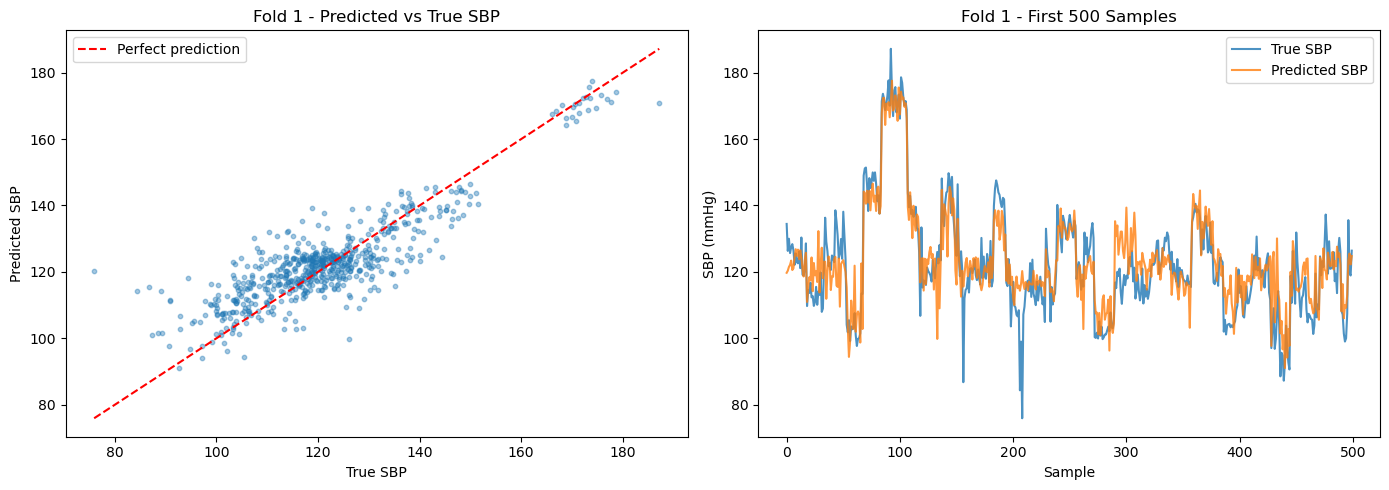

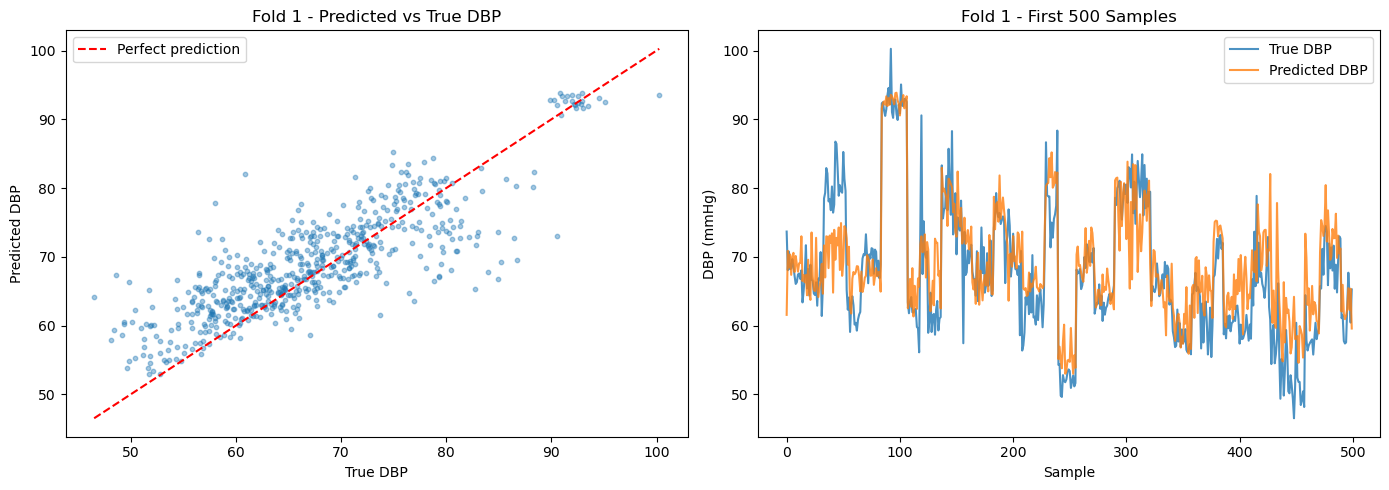


Fold 2/5
 Epoch 1 | Train Loss SBP: 192.0231 | Train Loss DBP: 85.9127
 Epoch 2 | Train Loss SBP: 137.8682 | Train Loss DBP: 46.4808
 Epoch 3 | Train Loss SBP: 118.0080 | Train Loss DBP: 42.8070
 Epoch 4 | Train Loss SBP: 110.4440 | Train Loss DBP: 38.8805
 Epoch 5 | Train Loss SBP: 105.9883 | Train Loss DBP: 35.8219
 Epoch 6 | Train Loss SBP: 103.6648 | Train Loss DBP: 35.2065
 Epoch 7 | Train Loss SBP: 99.8126 | Train Loss DBP: 34.3777
 Epoch 8 | Train Loss SBP: 91.2500 | Train Loss DBP: 31.4319
 Epoch 9 | Train Loss SBP: 87.3070 | Train Loss DBP: 30.6554
 Epoch 10 | Train Loss SBP: 85.7648 | Train Loss DBP: 30.1960
 Epoch 11 | Train Loss SBP: 86.0972 | Train Loss DBP: 29.9697
 Epoch 12 | Train Loss SBP: 87.0510 | Train Loss DBP: 28.8358
 Epoch 13 | Train Loss SBP: 81.1546 | Train Loss DBP: 27.4476
 Epoch 14 | Train Loss SBP: 75.0081 | Train Loss DBP: 27.4330
 Epoch 15 | Train Loss SBP: 75.4390 | Train Loss DBP: 27.0028
 Epoch 16 | Train Loss SBP: 71.9146 | Train Loss DBP: 25.8720
 

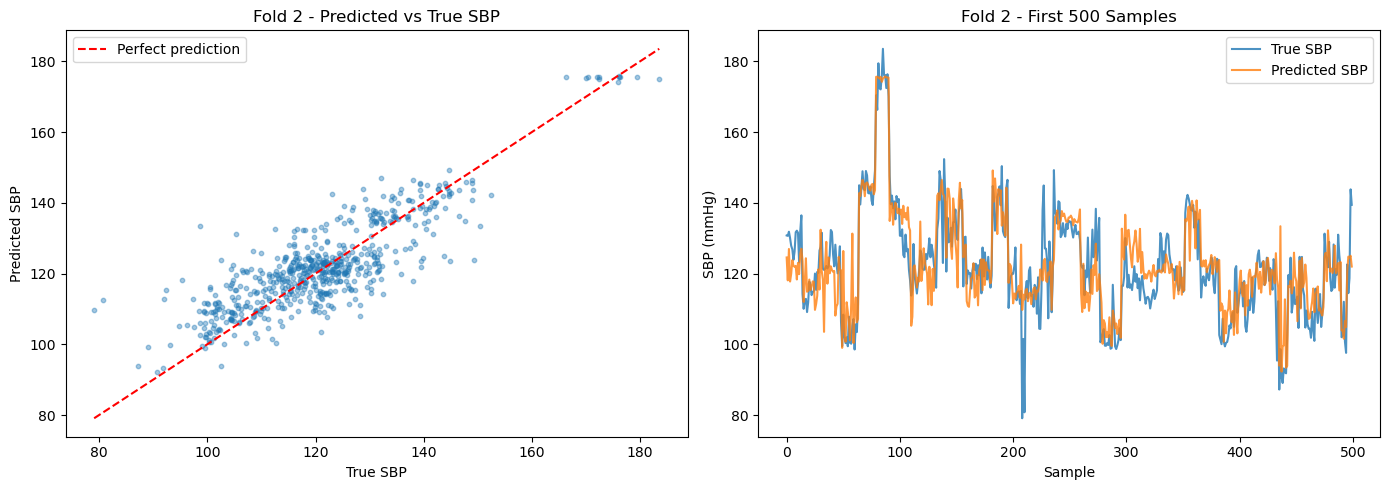

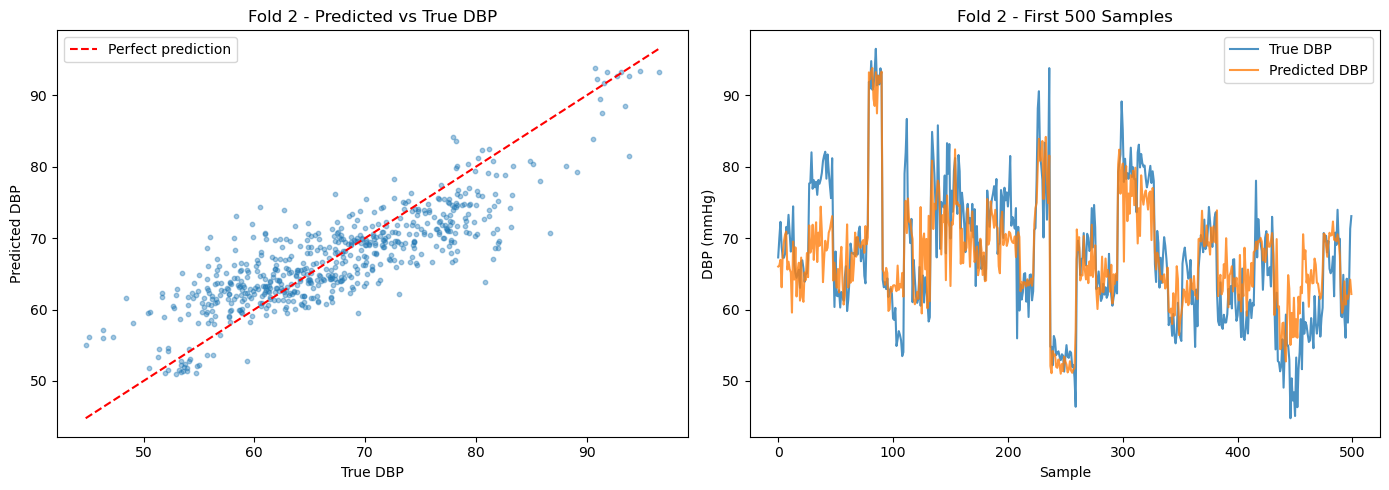


Fold 3/5
 Epoch 1 | Train Loss SBP: 185.1698 | Train Loss DBP: 76.8381
 Epoch 2 | Train Loss SBP: 129.8508 | Train Loss DBP: 47.7593
 Epoch 3 | Train Loss SBP: 110.5215 | Train Loss DBP: 42.3554
 Epoch 4 | Train Loss SBP: 104.4097 | Train Loss DBP: 36.7622
 Epoch 5 | Train Loss SBP: 98.5570 | Train Loss DBP: 34.8200
 Epoch 6 | Train Loss SBP: 94.4185 | Train Loss DBP: 32.7641
 Epoch 7 | Train Loss SBP: 91.5200 | Train Loss DBP: 31.2252
 Epoch 8 | Train Loss SBP: 89.2253 | Train Loss DBP: 31.0709
 Epoch 9 | Train Loss SBP: 83.2923 | Train Loss DBP: 30.2034
 Epoch 10 | Train Loss SBP: 76.3933 | Train Loss DBP: 28.8096
 Epoch 11 | Train Loss SBP: 77.6223 | Train Loss DBP: 27.8386
 Epoch 12 | Train Loss SBP: 72.6733 | Train Loss DBP: 27.2962
 Epoch 13 | Train Loss SBP: 75.2995 | Train Loss DBP: 26.3304
 Epoch 14 | Train Loss SBP: 70.2068 | Train Loss DBP: 27.0025
 Epoch 15 | Train Loss SBP: 67.4695 | Train Loss DBP: 26.5583
 Epoch 16 | Train Loss SBP: 66.8989 | Train Loss DBP: 25.9735
 Ep

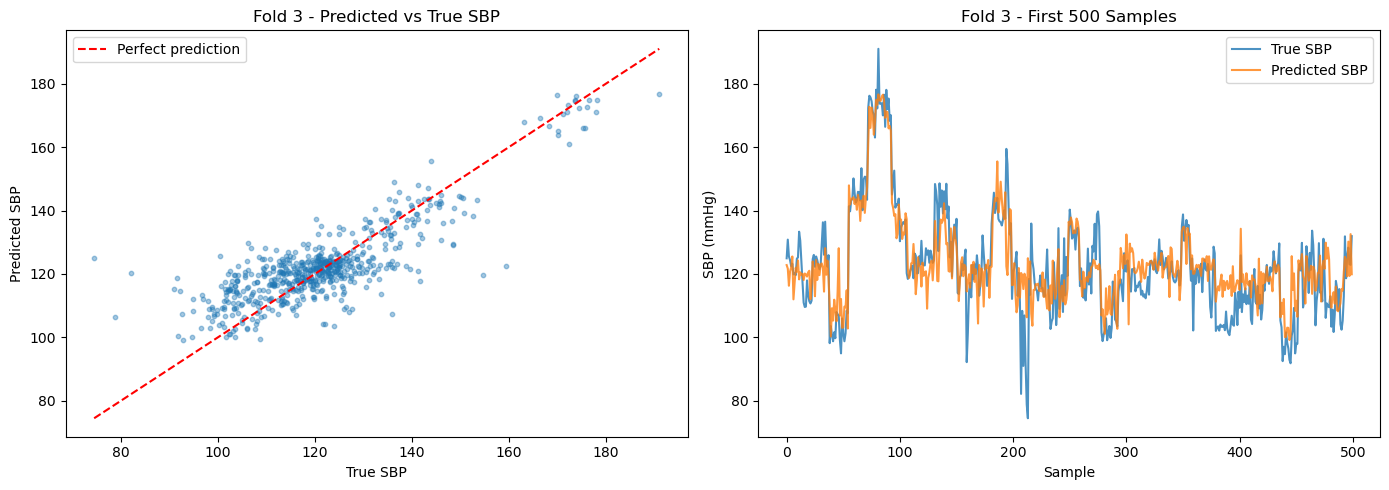

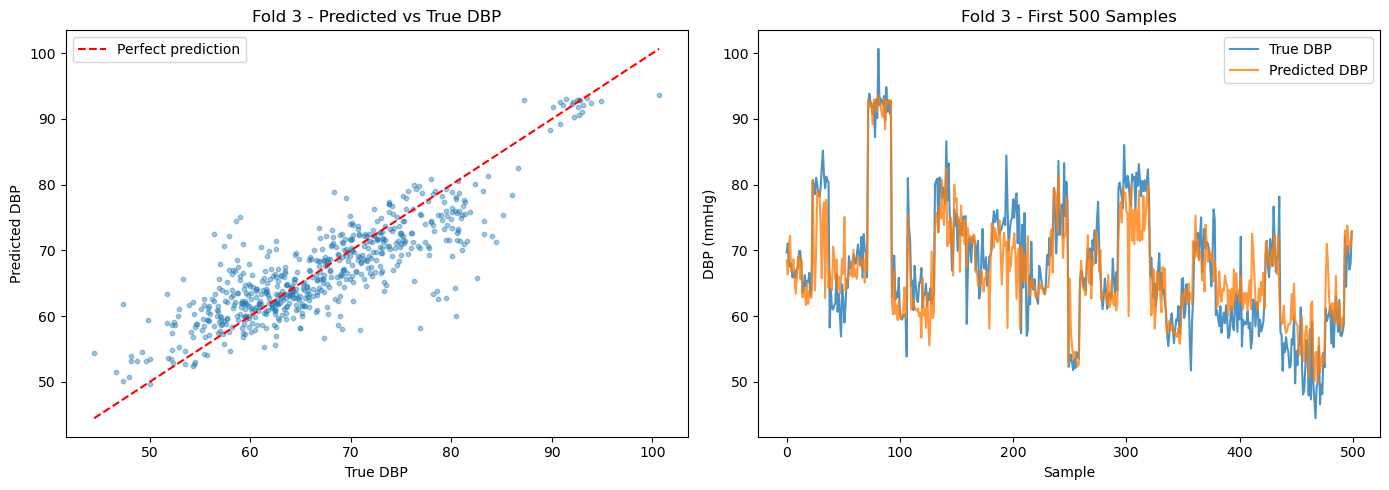


Fold 4/5
 Epoch 1 | Train Loss SBP: 203.6333 | Train Loss DBP: 73.4201
 Epoch 2 | Train Loss SBP: 132.4906 | Train Loss DBP: 49.8794
 Epoch 3 | Train Loss SBP: 113.4824 | Train Loss DBP: 42.9235
 Epoch 4 | Train Loss SBP: 99.7592 | Train Loss DBP: 38.1387
 Epoch 5 | Train Loss SBP: 99.3080 | Train Loss DBP: 35.9468
 Epoch 6 | Train Loss SBP: 92.5310 | Train Loss DBP: 34.4201
 Epoch 7 | Train Loss SBP: 92.7000 | Train Loss DBP: 31.6787
 Epoch 8 | Train Loss SBP: 84.8605 | Train Loss DBP: 31.3292
 Epoch 9 | Train Loss SBP: 87.2535 | Train Loss DBP: 30.2299
 Epoch 10 | Train Loss SBP: 81.1914 | Train Loss DBP: 28.7815
 Epoch 11 | Train Loss SBP: 79.8688 | Train Loss DBP: 28.9887
 Epoch 12 | Train Loss SBP: 77.9346 | Train Loss DBP: 28.0480
 Epoch 13 | Train Loss SBP: 75.5648 | Train Loss DBP: 26.3057
 Epoch 14 | Train Loss SBP: 74.8227 | Train Loss DBP: 27.0983
 Epoch 15 | Train Loss SBP: 72.5958 | Train Loss DBP: 27.3571
 Epoch 16 | Train Loss SBP: 69.6699 | Train Loss DBP: 26.5858
 Epo

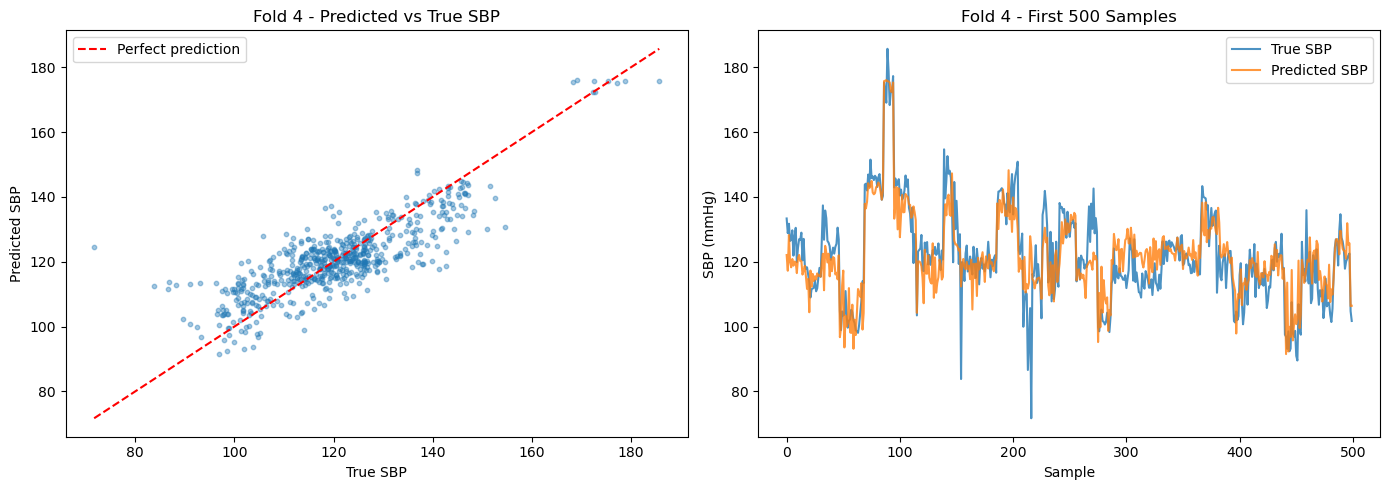

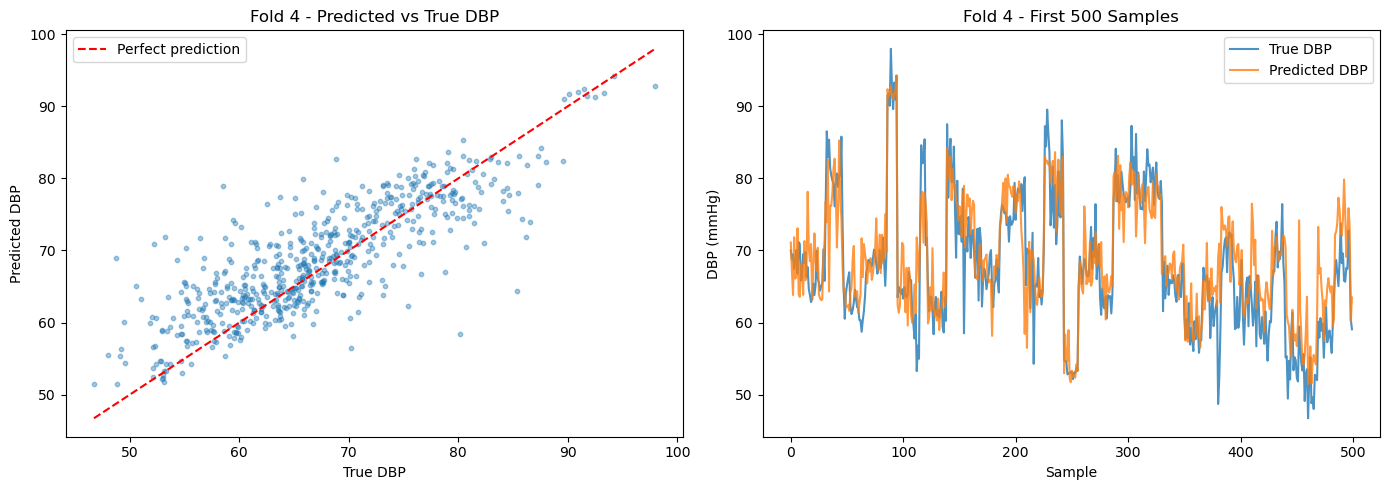


Fold 5/5
 Epoch 1 | Train Loss SBP: 175.4104 | Train Loss DBP: 79.8341
 Epoch 2 | Train Loss SBP: 123.9143 | Train Loss DBP: 53.8767
 Epoch 3 | Train Loss SBP: 108.1076 | Train Loss DBP: 45.8115
 Epoch 4 | Train Loss SBP: 106.4066 | Train Loss DBP: 40.7894
 Epoch 5 | Train Loss SBP: 98.0037 | Train Loss DBP: 37.0551
 Epoch 6 | Train Loss SBP: 95.2580 | Train Loss DBP: 35.8164
 Epoch 7 | Train Loss SBP: 90.4283 | Train Loss DBP: 32.6495
 Epoch 8 | Train Loss SBP: 84.1335 | Train Loss DBP: 33.0025
 Epoch 9 | Train Loss SBP: 80.0588 | Train Loss DBP: 30.9023
 Epoch 10 | Train Loss SBP: 77.2491 | Train Loss DBP: 30.5284
 Epoch 11 | Train Loss SBP: 76.5228 | Train Loss DBP: 29.8719
 Epoch 12 | Train Loss SBP: 76.3238 | Train Loss DBP: 28.4403
 Epoch 13 | Train Loss SBP: 73.5673 | Train Loss DBP: 27.5217
 Epoch 14 | Train Loss SBP: 66.8803 | Train Loss DBP: 28.2072
 Epoch 15 | Train Loss SBP: 68.6343 | Train Loss DBP: 26.6007
 Epoch 16 | Train Loss SBP: 68.6772 | Train Loss DBP: 27.1701
 Ep

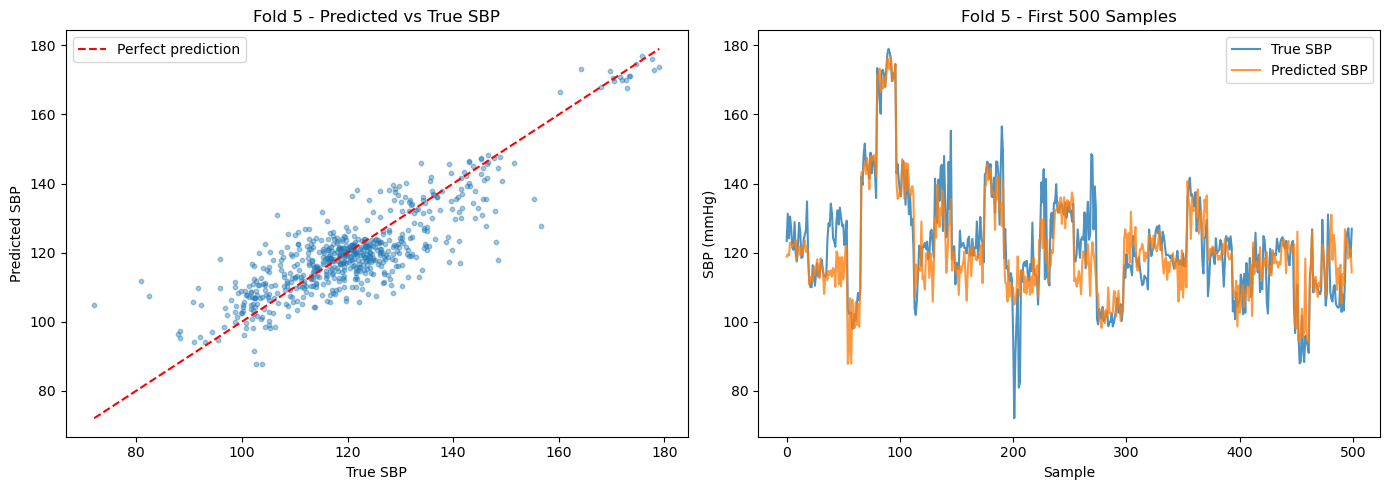

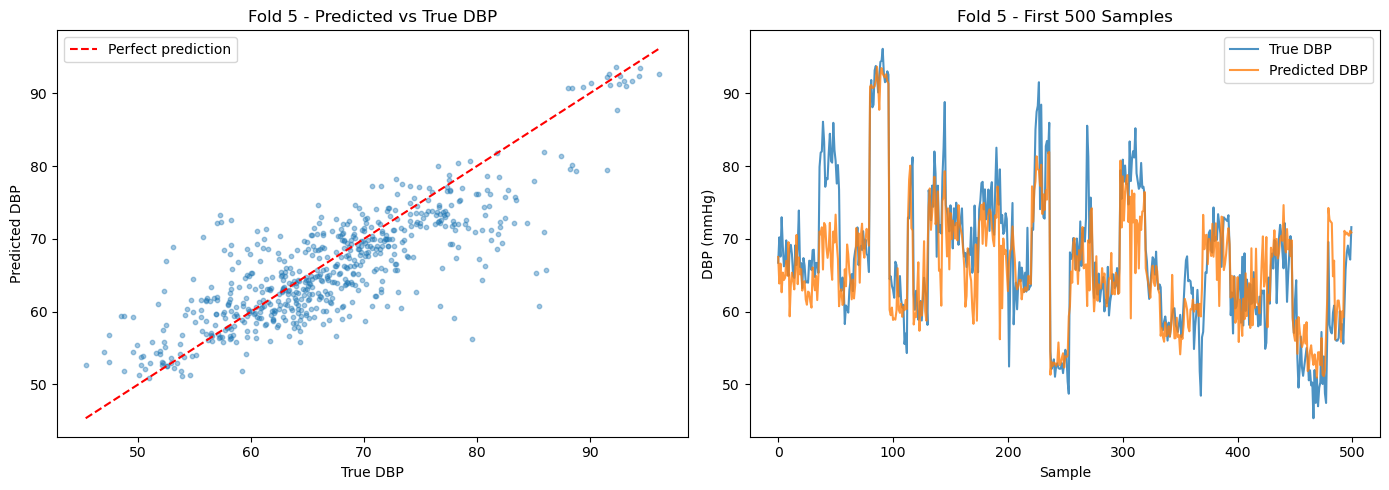


[spikegen] Final CV MAE's: 
SBP: 6.0907 ± 0.1492
DBP: 3.9164 ± 0.1919


In [93]:
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")
most_important_features = ["TdiaToEnd","T_a_norm","S4_norm","TSystoDiaRise", "ppg_histogram_down_2","S4","ppg4_histogram_down_5","T_e_norm","ppg3_histogram_down_8","usdc_2"]


with open("results_RF_importances/rf_results.pkl", "rb") as f:
    ranking = pickle.load(f)

# top_features_SBP = [f for (f, _) in ranking["sbp_ranking"][:30]]
# top_features_DBP = [f for (f, _) in ranking["dbp_ranking"][:30]]

top_features_SBP = [f for (f, _) in ranking["sbp_ranking_pearson"][:27]]
top_features_DBP = [f for (f, _) in ranking["dbp_ranking_pearson"][:27]]

batch_size = 32
num_epochs = 20
num_inputs = 27
num_hidden = 128
num_hidden2 = 64
num_outputs = 100
topk_sbp = 10
topk_dbp = 10

useStratifiedSampling = False
num_bins = 10
max_per_bin = 300

beta_val = 0.95
num_folds = 5
eps = 1e-8

preferred_values_sbp = torch.linspace(70, 190, 100).to(device)
preferred_values_dbp = torch.linspace(45, 101, 100).to(device)

results = {}
# ENCODING_METHODS = ['spikegen', 'uniform', 'beta']
ENCODING_METHODS = ['spikegen']

all_data, fold_indices = make_stratified_folds(num_folds=num_folds)

for encoding_method in ENCODING_METHODS:
    print(f"\n{'='*60}")
    print(f" ENCODING METHOD: {encoding_method.upper()}")
    print(f"{'='*60}")
    
    #loss_fn = SF.
    loss_fn = nn.MSELoss()
    firing_rate_loss_fn = SF.mse_count_loss(correct_rate=0.8, incorrect_rate=0.2)
    #loss_fn = nn.L1Loss() 
    
    cv_mae_sbp = 0.0    # Cross Validation Mean Absolute Error for SBP
    cv_mae_dbp = 0.0
    cv_total_samples = 0
    fold_maes_sbp = []  # To collect per-fold MAE
    fold_maes_dbp = []


    for fold in range(num_folds):
        print(f"\nFold {fold + 1}/{num_folds}")

        all_predictions_sbp = []    # For visualization
        all_true_sbp = []
        all_predictions_dbp = []
        all_true_dbp = []
        
        #net_sbp = Net(num_inputs, num_hidden, num_hidden2, num_outputs, beta_val, encoding_method).to(device)
        #net_dbp = Net(num_inputs, num_hidden, num_hidden2, num_outputs, beta_val, encoding_method).to(device)
        net_sbp = Net(num_inputs, num_hidden, num_hidden2, num_outputs, beta_val, num_steps=100).to(device)
        net_dbp = Net(num_inputs, num_hidden, num_hidden2, num_outputs, beta_val, num_steps=100).to(device)
        
        params_before = {name: param.clone().detach() for name, param in net_sbp.named_parameters()}

        optimizer_sbp = optim.Adam(net_sbp.parameters(), lr=5e-4)
        optimizer_dbp = optim.Adam(net_dbp.parameters(), lr=5e-4)

        #test_data  = load_data(fold)
        #train_data = pd.concat([load_data(i) for i in range(num_folds) if i != fold])

        train_idx, test_idx = fold_indices[fold]
        train_data = all_data.iloc[train_idx].reset_index(drop=True)
        test_data  = all_data.iloc[test_idx].reset_index(drop=True)

        if useStratifiedSampling == True:
            # Stratified sampling (bin by SBP)
            combined_df = train_data.copy()
            combined_df['SP_bin'] = pd.cut(combined_df.iloc[:, 2], bins=num_bins, duplicates='drop')

            train_data = (
                combined_df
                .groupby('SP_bin', group_keys=False)
                .apply(lambda g: g.sample(min(len(g), max_per_bin), random_state=2))
                .reset_index(drop=True)
            )

            if 'SP_bin' in train_data.columns:
                train_data = train_data.drop(columns='SP_bin')


        X_train_sbp = torch.tensor(train_data[top_features_SBP].values, dtype=torch.float32)
        X_train_dbp = torch.tensor(train_data[top_features_DBP].values, dtype=torch.float32)
        X_test_sbp = torch.tensor(test_data[top_features_SBP].values, dtype=torch.float32)
        X_test_dbp = torch.tensor(test_data[top_features_DBP].values, dtype=torch.float32)
        y_train = torch.tensor(train_data.iloc[:, 2:4].values, dtype=torch.float32)
        y_test = torch.tensor(test_data.iloc[:, 2:4].values, dtype=torch.float32)
        
        # per feature SBP normalization
        X_min_sbp = X_train_sbp.min(dim=0).values
        X_max_sbp = X_train_sbp.max(dim=0).values
        X_train_sbp = (X_train_sbp - X_min_sbp) / (X_max_sbp - X_min_sbp + 1e-8)
        X_test_sbp  = (X_test_sbp  - X_min_sbp) / (X_max_sbp - X_min_sbp + 1e-8)

        # per feature DBP normalization
        X_min_dbp = X_train_dbp.min(dim=0).values
        X_max_dbp = X_train_dbp.max(dim=0).values
        X_train_dbp = (X_train_dbp - X_min_dbp) / (X_max_dbp - X_min_dbp + 1e-8)
        X_test_dbp  = (X_test_dbp  - X_min_dbp) / (X_max_dbp - X_min_dbp + 1e-8)
        
        train_loader = DataLoader(
            TensorDataset(X_train_sbp, X_train_dbp, y_train),
            batch_size=batch_size, shuffle=True
        )
        test_loader = DataLoader(
            TensorDataset(X_test_sbp, X_test_dbp, y_test),
            batch_size=batch_size, shuffle=False
        )

        # Training
        for epoch in range(num_epochs):
            net_sbp.train()
            net_dbp.train()
            num_batches = 0
            total_train_loss_sbp = 0
            total_train_loss_dbp = 0
            
            for x_sbp, x_dbp, y in train_loader:
                x_sbp = x_sbp.to(device)
                x_dbp = x_dbp.to(device)
                y = y.to(device)

                optimizer_sbp.zero_grad()
                optimizer_dbp.zero_grad()

                # SBP
                '''
                spk_sbp = [time_steps, batch_size, 100], these is the spiking activity of the model
                fr_sbp = [batch_size, 100], here we average over the timesteps
                topk_idx = select the top k most active neurons (spiked the most on average)
                fr_top = gather their firing rates
                pv_top = gather their pressure values
                pred_sbp = final prediction

                Why Top-K during training? 
                It focuses the loss signal on the neurons that are actually firing meaningfully, ignoring the noisy low-activity neurons.
                This makes the neural network produce a sparse but confident representation. 
                '''
                spk_sbp = net_sbp(x_sbp)
                fr_sbp = spk_sbp.mean(0)
                topk_idx = torch.topk(fr_sbp, topk_sbp, dim=1)[1]
                fr_top = torch.gather(fr_sbp, 1, topk_idx)
                pv_top = preferred_values_sbp[topk_idx]
                pred_sbp = (fr_top * pv_top).sum(1) / (fr_top.sum(1) + eps)

                # DBP
                spk_dbp = net_dbp(x_dbp)
                fr_dbp = spk_dbp.mean(0)
                topk_idx = torch.topk(fr_dbp, topk_dbp, dim=1)[1]
                fr_top = torch.gather(fr_dbp, 1, topk_idx)
                pv_top = preferred_values_dbp[topk_idx]
                pred_dbp = (fr_top * pv_top).sum(1) / (fr_top.sum(1) + eps)

                loss_sbp = loss_fn(pred_sbp, y[:, 0])
                loss_dbp = loss_fn(pred_dbp, y[:, 1])

                loss_sbp.backward()
                
                torch.nn.utils.clip_grad_norm_(net_sbp.parameters(), max_norm=1.0)
                optimizer_sbp.step()

                loss_dbp.backward()
                torch.nn.utils.clip_grad_norm_(net_dbp.parameters(), max_norm=1.0)
                optimizer_dbp.step()


                total_train_loss_sbp += loss_sbp.item()
                total_train_loss_dbp += loss_dbp.item()
                num_batches += 1
            print(f" Epoch {epoch + 1} | Train Loss SBP: {total_train_loss_sbp / num_batches:.4f} "
                  f"| Train Loss DBP: {total_train_loss_dbp / num_batches:.4f}")
            '''
            print(f" Epoch {epoch + 1} | Train Loss SBP: {total_train_loss_sbp / num_batches:.4f} "
                  f"| Train Loss DBP: {total_train_loss_dbp / num_batches:.4f}")
            if fold == 0 and (epoch == 0 or epoch == num_epochs - 1):
                print(f"--- Weight changes after epoch {epoch+1} ---")
                for name, param in net_sbp.named_parameters():
                    diff = (param.detach() - params_before[name]).abs().mean().item()
                    print(f"{name}: mean weight change = {diff:.6f}")
            '''

        # Evaluation
        net_sbp.eval()
        net_dbp.eval()
        total_mae_sbp = 0
        total_mae_dbp = 0
        total_samples = 0
        true_sbp_list = []
        pred_sbp_list = []
        true_dbp_list = []
        pred_dbp_list = []

        with torch.no_grad():
            for x_sbp, x_dbp, y in test_loader:
                x_sbp = x_sbp.to(device)
                x_dbp = x_dbp.to(device)
                y = y.to(device)

                '''
                Here we dont have the topk neurons anymore, we take the average over all 100 neurons. 
                '''
                spk_sbp = net_sbp(x_sbp)
                fr_sbp = spk_sbp.mean(0)
                
                topk_idx = torch.topk(fr_sbp, topk_sbp, dim=1)[1]
                fr_top = torch.gather(fr_sbp, 1, topk_idx)
                pv_top = preferred_values_sbp[topk_idx]
                pred_sbp = (fr_top * pv_top).sum(1) / (fr_top.sum(1) + eps)

                #pred_sbp = (fr_sbp * preferred_values_sbp).sum(1) / (fr_sbp.sum(1) + eps)

                spk_dbp = net_dbp(x_dbp)
                fr_dbp = spk_dbp.mean(0)
                
                topk_idx = torch.topk(fr_dbp, topk_dbp, dim=1)[1]
                fr_top = torch.gather(fr_dbp, 1, topk_idx)
                pv_top = preferred_values_dbp[topk_idx]
                pred_dbp = (fr_top * pv_top).sum(1) / (fr_top.sum(1) + eps)
                
                #pred_dbp = (fr_dbp * preferred_values_dbp).sum(1) / (fr_dbp.sum(1) + eps)

                mae_sbp = torch.abs(pred_sbp - y[:, 0]).sum().item()
                mae_dbp = torch.abs(pred_dbp - y[:, 1]).sum().item()

                true_sbp_list.extend(y[:,0].cpu().numpy())
                pred_sbp_list.extend(pred_sbp.cpu().numpy())

                true_dbp_list.extend(y[:,1].cpu().numpy())
                pred_dbp_list.extend(pred_dbp.cpu().numpy())

                total_mae_sbp += mae_sbp
                total_mae_dbp += mae_dbp
                total_samples += y.shape[0]

        fold_mae_sbp = total_mae_sbp / total_samples
        fold_mae_dbp = total_mae_dbp / total_samples   

        fold_maes_sbp.append(fold_mae_sbp)
        fold_maes_dbp.append(fold_mae_dbp)

        cv_mae_sbp += total_mae_sbp
        cv_mae_dbp += total_mae_dbp
        cv_total_samples += total_samples
        print(f"Generalization Error SBP = {total_mae_sbp / total_samples:.4f}, Generalization Error DBP = {total_mae_dbp / total_samples:.4f}")
        plot_predictions(np.array(true_sbp_list), np.array(pred_sbp_list), "SBP", fold, 500)
        plot_predictions(np.array(true_dbp_list), np.array(pred_dbp_list), "DBP", fold, 500)

    results[encoding_method] = (cv_mae_sbp, cv_mae_dbp)

    print(f"\n[{encoding_method}] Final CV MAE's: \nSBP: {cv_mae_sbp / cv_total_samples:.4f} ± {np.std(fold_maes_sbp):.4f}\nDBP: {cv_mae_dbp / cv_total_samples:.4f} ± {np.std(fold_maes_dbp):.4f}")